# %% [markdown]
# 📊 Capítulo 5: Pairs Trading
*La danza de los correlacionados — Arbitraje estadístico con cointegración*
 
**Estrategia:** Identificar pares de activos cointegrados (KO/PEP, XOM/CVX, BAC/JPM, HD/LOW, MCD/YUM). Cuando el z-score del spread supera +2 o cae por debajo de -2, abrir posición market-neutral (largo en el barato, corto en el caro). Cerrar cuando el z-score vuelve a 0 o cuando se detecta ruptura de cointegración.

**Universo:** 5 pares clásicos de empresas con modelos de negocio similares y datos desde 2000.

**Objetivo:** Demostrar cómo el arbitraje estadístico genera rentabilidad descorrelada del mercado (beta cercana a 0), actuando como un satélite de alpha puro en un modelo Core-Satellite.


##  Celda 1: BLOQUE 0

In [1]:
# ==============================================================================
# BLOQUE 0: CONFIGURACIÓN DE LA ESTRATEGIA — PAIRS TRADING
# ==============================================================================

CAPITAL_INICIAL      = 10000
COSTE_TRANSACCION    = 0.001       # 0.1% por operación
BENCHMARK            = 'SPY'
BANDA_NO_TRADE       = 0.02        # Banda no-trade del motor (2%)

FECHA_INICIO = None
FECHA_FIN    = None

# --- Parámetros Pairs Trading ---
P_VALOR_MAXIMO       = 0.10
VENTANA_ZSCORE       = 60
VENTANA_HEDGE_RATIO  = 126
VENTANA_ADF          = 252
UMBRAL_ENTRADA       = 2.0
UMBRAL_SALIDA        = 0.5
UMBRAL_STOP          = 3.5
MAX_PARES_SIMULTANEOS = 3
TAMANO_POSICION      = 0.15  # Reducido de 0.20 a 0.15 (más conservador)
NORMALIZAR_VOLATILIDAD = False

VENTANA_MINIMA_DIAS  = 504
FACTOR_RIESGO_MAX    = 2.0   # NUEVO: límite para evitar apalancamiento



# --- Pares candidatos ---
PARES_CANDIDATOS = [
    ('KO', 'PEP'),
    ('EWA', 'EWC'),
    ('GLD', 'GDX'),  # ← Oro físico vs mineras (clásico)
    ('XOM', 'CVX'),
    ('HD', 'LOW'),
    ('BAC', 'JPM'),
]

# --- Universo de activos ---
UNIVERSO_PAIRS = {
    'consumo': {
        'Coca-Cola':      {'isin': 'KO',  'ticker': 'KO'},
        'PepsiCo':        {'isin': 'PEP', 'ticker': 'PEP'},
    },
    'internacional': {    
        'iShares MSCI Australia': {'isin': 'EWA', 'ticker': 'EWA'},
        'iShares MSCI Canada':    {'isin': 'EWC', 'ticker': 'EWC'},
    },
    'materias_primas': {
        'SPDR Gold Trust':        {'isin': 'GLD', 'ticker': 'GLD'},
        'VanEck Vectors Gold Miners': {'isin': 'GDX', 'ticker': 'GDX'},
    },
    'energia': {
        'ExxonMobil': {'isin': 'XOM', 'ticker': 'XOM'},
        'Chevron':    {'isin': 'CVX', 'ticker': 'CVX'},
    },
    'retail': {
        'Home Depot': {'isin': 'HD', 'ticker': 'HD'},
        "Lowe's":    {'isin': 'LOW', 'ticker': 'LOW'},
    },
    'finanzas': {  # ← ✅ NUEVO
        'Bank of America': {'isin': 'BAC', 'ticker': 'BAC'},
        'JPMorgan Chase':  {'isin': 'JPM', 'ticker': 'JPM'},
    }
}

print("✅ Configuración Pairs Trading cargada:")
print(f"   • Capital inicial: {CAPITAL_INICIAL:,.0f} €")
print(f"   • Pares candidatos: {len(PARES_CANDIDATOS)}")
print(f"   • Umbral entrada: ±{UMBRAL_ENTRADA}")
print(f"   • Banda No-Trade: {BANDA_NO_TRADE:.0%}")

✅ Configuración Pairs Trading cargada:
   • Capital inicial: 10,000 €
   • Pares candidatos: 6
   • Umbral entrada: ±2.0
   • Banda No-Trade: 2%


## BLOQUE 1: ENTORNO E IMPORTACIONES

In [2]:
# ==============================================================================
# BLOQUE 1: ENTORNO E IMPORTACIONES
# ==============================================================================

import sys, os, warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.stattools import coint, adfuller

IN_COLAB = "google.colab" in sys.modules
print(f"Entorno: {'Google Colab' if IN_COLAB else 'Local / VS Code'}")

def buscar_core():
    try:
        import ipykernel
        try:
            from jupyter_server import serverapp as app_module
        except ImportError:
            from notebook import notebookapp as app_module
        import json, re, urllib.request
        connection_file = os.path.basename(ipykernel.get_connection_file())
        match = re.search(r'kernel-(.*)\.json', connection_file)
        if match:
            kernel_id = match.group(1)
            for srv in app_module.list_running_servers():
                try:
                    url = srv['url'] + 'api/sessions'
                    token = srv.get('token', '')
                    headers = {'Authorization': f'token {token}'} if token else {}
                    req = urllib.request.Request(url, headers=headers)
                    with urllib.request.urlopen(req, timeout=2) as resp:
                        sessions = json.loads(resp.read())
                    for sess in sessions:
                        if sess.get('kernel', {}).get('id') == kernel_id:
                            ruta_nb = os.path.join(srv['root_dir'], sess['notebook']['path'])
                            ruta_dir = os.path.dirname(os.path.abspath(ruta_nb))
                            actual = Path(ruta_dir)
                            for parent in [actual] + list(actual.parents):
                                if (parent / 'core').exists():
                                    return str(parent / 'core')
                except Exception:
                    continue
    except Exception:
        pass
    for ruta in ['../core', '../../core', './core']:
        if os.path.isdir(ruta):
            return os.path.abspath(ruta)
    return None

if "google.colab" in sys.modules:
    import subprocess
    _REPO = "/content/Estrategias_No_Convencionales"
    if not os.path.isdir(os.path.join(_REPO, "core")):
        print("Clonando repo...")
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/akitxu/Estrategias_No_Convencionales.git", _REPO], check=True)
    os.chdir(os.path.join(_REPO, "notebooks"))

RUTA_CORE = buscar_core()
if RUTA_CORE and os.path.isdir(RUTA_CORE):
    sys.path.insert(0, os.path.dirname(RUTA_CORE))
    print(f"Carpeta 'core' localizada: {RUTA_CORE}")
else:
    print("⚠️ No se encontró 'core'.")

try:
    from core import (
        GestorProyecto, GestorDatos, MotorBacktestDinamico,
        CalculadorMetricas, CalculadorMetricasExtras, GeneradorInformes
    )
    print("✅ Módulos importados")
except ImportError as e:
    print(f" Error: {e}")
    raise

BASE_DIR = os.path.dirname(RUTA_CORE) if RUTA_CORE else os.getcwd()

Entorno: Local / VS Code
Carpeta 'core' localizada: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/core
✅ Módulos importados


## BLOQUE 2: LIMPIEZA DE DIRECTORIOS

In [3]:
# ==============================================================================
# BLOQUE 2: LIMPIEZA DE DIRECTORIOS
# ==============================================================================

gestor_proyecto = GestorProyecto(base_dir_manual=BASE_DIR)
gestor_proyecto.imprimir_resumen()
gestor_proyecto.menu_limpieza_directorios()

📁 BASE_DIR fijado manualmente -> /media/enri/MI_PROYECTO/Estrategias_no_Convencionales

🔍 ENTORNO CONFIGURADO
📂 Base: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales
📁 CORE                : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/core
📁 CHAPTERS            : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/chapters
📁 LOGS                : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/logs
📁 DATOS               : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos
📁 OUTPUTS             : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs
📁 CARTERAS            : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/carteras
📁 DATOS_CSV           : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_csv
📁 DATOS_FI_GESTORA    : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_fi_gestora
📁 DATOS_FI_INVESTING  : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_fi_investing
📁 DATOS_FI_MYI


¿Qué directorios deseas VACIAR? (ej: 3,5,7 / 'todos' / 'ninguno'):  5



🧹 Iniciando limpieza...
   🗑️  Vaciando 'DATOS_CSV'...
      ✅ 'DATOS_CSV' limpiado.


## BLOQUE 3: GESTIÓN DE FECHAS

In [4]:
# ==============================================================================
# BLOQUE 3: GESTIÓN DE FECHAS
# ==============================================================================

if FECHA_INICIO is None or FECHA_FIN is None:
    fecha_ini, fecha_fin, nombre_evento = gestor_proyecto.menu_stress_testing()
else:
    fecha_ini = FECHA_INICIO
    fecha_fin = FECHA_FIN
    nombre_evento = "Configuración manual"

try:
    fecha_ini = pd.to_datetime(fecha_ini)
    fecha_fin = pd.to_datetime(fecha_fin)
    if fecha_ini >= fecha_fin:
        raise ValueError("La fecha inicio debe ser anterior a la fecha fin")
except Exception as e:
    print(f"❌ ERROR EN FECHAS: {e}. Usando valores por defecto.")
    fecha_ini = pd.Timestamp('2010-01-01')
    fecha_fin = pd.Timestamp('2023-12-31')

print(f"Rango temporal: {nombre_evento} | {fecha_ini.date()} → {fecha_fin.date()}")


📉 ANÁLISIS DE ESTRÉS (STRESS TESTING)
  1. Crisis Punto Com (2000-2002)
  2. Crisis Financiera Mundial (2007-2009)
  3. Crisis Deuda Soberana (2010-2012)
  4. Crisis Financiera China (2015-2016)
  5. Crisis COVID-19 (2020)
  6. Subida Tipos / Inflación (2022-2023)
  7. Periodo Personalizado
  8. Histórico Completo (1999-Hoy)



Introduce tu elección (1-8) [Por defecto 8]:  7
  Fecha inicio (YYYY-MM-DD):  2010-01-04
  Fecha fin (YYYY-MM-DD):  2023-12-30



🎯 Evento: Periodo Personalizado | Inicio: 2010-01-04 | Fin: 2023-12-30

Rango temporal: Periodo Personalizado | 2010-01-04 → 2023-12-30


## BLOQUE 4: MENÚ DEL GESTOR DE DATOS

In [5]:
# ==============================================================================
# BLOQUE 4: MENÚ DEL GESTOR DE DATOS
# ==============================================================================

gestor = GestorDatos(
    diccionario_datos=UNIVERSO_PAIRS,
    fecha_inicio=str(fecha_ini),
    fecha_fin=str(fecha_fin),
    gestor_proyecto=gestor_proyecto
)

continuar = gestor.menu()
if not continuar:
    raise SystemExit("Usuario canceló.")
else:
    print("✅ Datos preparados.")


 SISTEMA: IMPORTAR · NORMALIZAR · CARTERAS
1. Descargar/Actualizar cotizaciones (Yahoo)
2. Importar ficheros Renta 4
3. Normalizar CSVs del directorio
4. Crear cartera interactiva (Pide nombre y descarga CSVs)
5. Cargar cartera existente (Lista carteras guardadas)
6. Ejecutar Estrategia (Continuar al Backtest)
7. Salir
8. 🔄 Sincronizar datos con período actual (re-descarga si es necesario)


Selecciona una opción (1-8):  1



🗑️ Limpiando CSVs antiguos y descargando desde Yahoo Finance...

📊 Procesando 12 activos...

   📊 Coca-Cola
      ✅ Descargado con ticker: KO

   📊 PepsiCo
      ✅ Descargado con ticker: PEP

   📊 iShares MSCI Australia
      ✅ Descargado con ticker: EWA

   📊 iShares MSCI Canada
      ✅ Descargado con ticker: EWC

   📊 SPDR Gold Trust
      ✅ Descargado con ticker: GLD

   📊 VanEck Vectors Gold Miners
      ✅ Descargado con ticker: GDX

   📊 ExxonMobil
      ✅ Descargado con ticker: XOM

   📊 Chevron
      ✅ Descargado con ticker: CVX

   📊 Home Depot
      ✅ Descargado con ticker: HD

   📊 Lowe's
      ✅ Descargado con ticker: LOW

   📊 Bank of America
      ✅ Descargado con ticker: BAC

   📊 JPMorgan Chase
      ✅ Descargado con ticker: JPM

📊 Resumen: 12 descargados, 0 omitidos



Presiona Enter para continuar... 



 SISTEMA: IMPORTAR · NORMALIZAR · CARTERAS
1. Descargar/Actualizar cotizaciones (Yahoo)
2. Importar ficheros Renta 4
3. Normalizar CSVs del directorio
4. Crear cartera interactiva (Pide nombre y descarga CSVs)
5. Cargar cartera existente (Lista carteras guardadas)
6. Ejecutar Estrategia (Continuar al Backtest)
7. Salir
8. 🔄 Sincronizar datos con período actual (re-descarga si es necesario)


Selecciona una opción (1-8):  6



✅ Datos aceptados para el backtest.
📝 No hay Excel cargado. Generando cartera automática (60/40) desde el diccionario...

🧼 INFORME DE LIMPIEZA DE DATOS


,Activo,ISIN,Filas,Desde,Hasta,Fuente
0,Coca-Cola,KO,3522,2010-01-04,2023-12-29,CSV
1,PepsiCo,PEP,3522,2010-01-04,2023-12-29,CSV
2,iShares MSCI Australia,EWA,3522,2010-01-04,2023-12-29,CSV
3,iShares MSCI Canada,EWC,3522,2010-01-04,2023-12-29,CSV
4,SPDR Gold Trust,GLD,3522,2010-01-04,2023-12-29,CSV
5,VanEck Vectors Gold Miners,GDX,3522,2010-01-04,2023-12-29,CSV
6,ExxonMobil,XOM,3522,2010-01-04,2023-12-29,CSV
7,Chevron,CVX,3522,2010-01-04,2023-12-29,CSV
8,Home Depot,HD,3522,2010-01-04,2023-12-29,CSV
9,Lowe's,LOW,3522,2010-01-04,2023-12-29,CSV


✅ 12 activos alineados para el Motor Backtest.

✅ Datos preparados.


## BLOQUE 5: ESCANEO DE COINTEGRACIÓN Y GENERADOR DE PESOS (CORREGIDO)

In [6]:
# ==============================================================================
# BLOQUE 5: ESCANEO DE COINTEGRACIÓN Y GENERADOR DE PESOS (v8 - Definitivo)
# ==============================================================================

print("\n" + "="*70)
print(" ESCANEO DE COINTEGRACIÓN (v8 - Definitivo)")
print("="*70)

# Variables globales
pares_validos = []
gemelologo = None

if gestor.precios_ajustados is None or gestor.precios_ajustados.empty:
    raise ValueError(" No hay precios ajustados. Ejecuta el Bloque 4 primero.")

dias = len(gestor.precios_ajustados)
if dias < VENTANA_MINIMA_DIAS:
    print(f"Ventana insuficiente ({dias}). Añadiendo warm-up...")
    años_warmup = max(2, int(np.ceil((VENTANA_MINIMA_DIAS - dias) / 252)))
    fecha_warmup = gestor.precios_ajustados.index[0] - pd.DateOffset(years=años_warmup)
    
    gestor_warmup = GestorDatos(
        diccionario_datos=UNIVERSO_PAIRS,
        fecha_inicio=fecha_warmup.strftime('%Y-%m-%d'),
        fecha_fin=str(fecha_fin),
        gestor_proyecto=gestor_proyecto
    )
    gestor_warmup.gestionar_descarga_cotizaciones()
    gestor_warmup._cartera_por_defecto()
    gestor_warmup.preparar_datos_motor()
    gestor = gestor_warmup
    print(f"Warm-up completado: {len(gestor.precios_ajustados)} filas.")
else:
    print("✅ Ventana suficiente.")

# Mapeo de tickers
mapeo_tickers = {}
for _, row in gestor.valores_seleccionados.iterrows():
    ticker = str(row.get('ticker', '')).strip().upper()
    nombre = str(row.get('nombre', '')).strip()
    nombre_limpio = nombre.replace(" ", "_").replace(".", "").replace(",", "")
    if ticker:
        mapeo_tickers[ticker] = nombre_limpio

# Preparar pares con columnas válidas
pares_con_columnas = []
for a, b in PARES_CANDIDATOS:
    col_a = mapeo_tickers.get(a)
    col_b = mapeo_tickers.get(b)
    if col_a and col_b and col_a in gestor.precios_ajustados.columns and col_b in gestor.precios_ajustados.columns:
        pares_con_columnas.append((col_a, col_b))
        print(f"   ✅ {a}/{b} → {col_a}/{col_b}")
    else:
        print(f"   ❌ {a}/{b}: columnas no encontradas")

if not pares_con_columnas:
    raise ValueError("❌ Ningún par válido encontrado.")

# Clase GemelologoRobusto
class GemelologoRobusto:
    def __init__(self, df_precios):
        self.df = df_precios
        
    def test_cointegracion(self, col_a, col_b, p_max=0.10):
        try:
            df = self.df[[col_a, col_b]].dropna()
            if len(df) < 100:
                return {'cointegrado': False, 'p_valor': 1.0}
            
            log_a = np.log(df[col_a])
            log_b = np.log(df[col_b])
            
            score, p_value, _ = coint(log_a.values, log_b.values)
            
            return {'cointegrado': p_value < p_max, 'p_valor': p_value}
        except Exception:
            return {'cointegrado': False, 'p_valor': 1.0}

    def calcular_hedge_ratio(self, serie_a, serie_b, ventana):
        try:
            log_a = np.log(serie_a.dropna())
            log_b = np.log(serie_b.dropna())
            common_idx = log_a.index.intersection(log_b.index)
            
            if len(common_idx) < ventana:
                return None
                
            df = pd.DataFrame({'a': log_a.loc[common_idx], 'b': log_b.loc[common_idx]}).tail(ventana)
            beta = np.polyfit(df['b'], df['a'], 1)[0]
            return beta
        except Exception:
            return None

    def calcular_spread(self, serie_a, serie_b, beta):
        log_a = np.log(serie_a.dropna())
        log_b = np.log(serie_b.dropna())
        common_idx = log_a.index.intersection(log_b.index)
        spread = log_a.loc[common_idx] - beta * log_b.loc[common_idx]
        return spread

    def calcular_zscore(self, spread, ventana):
        media = spread.rolling(window=ventana).mean()
        std = spread.rolling(window=ventana).std()
        return (spread - media) / std

    def detectar_ruptura(self, spread, ventana):
        try:
            last_window = spread.tail(ventana).dropna()
            if len(last_window) < 50:
                return False
            stat, p_value, _ = adfuller(last_window)
            return p_value > 0.10
        except Exception:
            return False

    def calcular_half_life(self, spread):
        try:
            spread = spread.dropna()
            if len(spread) < 50:
                return np.inf
            lag = spread.shift(1).dropna()
            delta = spread.diff().dropna()
            lag = lag.loc[delta.index]
            if len(lag) < 50:
                return np.inf
            lambda_coef = np.polyfit(lag, delta, 1)[0]
            if lambda_coef >= 0:
                return np.inf
            return -np.log(2) / lambda_coef
        except Exception:
            return np.inf

gemelologo = GemelologoRobusto(gestor.precios_ajustados)

# Escanear pares
print(f"\n🔬 Escaneando cointegración de {len(pares_con_columnas)} pares...")
for col_a, col_b in pares_con_columnas:
    res = gemelologo.test_cointegracion(col_a, col_b, P_VALOR_MAXIMO)
    
    if res['cointegrado']:
        log_a = np.log(gestor.precios_ajustados[col_a]).dropna()
        log_b = np.log(gestor.precios_ajustados[col_b]).dropna()
        common_idx = log_a.index.intersection(log_b.index)
        df = pd.DataFrame({'a': log_a.loc[common_idx], 'b': log_b.loc[common_idx]})
        beta = np.polyfit(df['b'], df['a'], 1)[0]
        spread = df['a'] - beta * df['b']
        half_life = gemelologo.calcular_half_life(spread)
        
        if half_life < np.inf and half_life > 0:
            pares_validos.append({
                'activo_a': col_a,
                'activo_b': col_b,
                'p_valor': res['p_valor'],
                'half_life': half_life
            })
            print(f"   ✅ {col_a}/{col_b} (p={res['p_valor']:.4f}, HL={half_life:.1f}d)")
        else:
            print(f"   ❌ {col_a}/{col_b} (p={res['p_valor']:.4f}, HL=infinito)")
    else:
        print(f"   ❌ {col_a}/{col_b} (p={res['p_valor']:.4f})")

print(f"\n📈 Pares operativos: {len(pares_validos)}")

# ✅ DEFINITIVO: Pesos 50/50 sin normalización
TAMANO_PAR = 0.10  # 10% del capital por par (5% largo + 5% corto)

# Generador de pesos v8 - Definitivo
def generador_pesos_pairs(fecha_actual, precios_hist, rent_hist, estado):
    activos = list(precios_hist.columns)
    pesos = {a: 0.0 for a in activos}  # ← RESET completo cada día
    
    if 'posiciones_abiertas' not in estado:
        estado['posiciones_abiertas'] = {}
    
    if not pares_validos:
        return pesos, estado

    for par_info in pares_validos:
        col_a = par_info['activo_a']
        col_b = par_info['activo_b']
        
        if col_a not in precios_hist.columns or col_b not in precios_hist.columns:
            continue
        
        # Calcular Beta Dinámica
        beta = gemelologo.calcular_hedge_ratio(
            precios_hist[col_a],
            precios_hist[col_b],
            VENTANA_HEDGE_RATIO
        )
        
        if beta is None or np.isnan(beta):
            continue
        
        # Calcular Spread y Z-Score
        spread = gemelologo.calcular_spread(precios_hist[col_a], precios_hist[col_b], beta)
        zscore_series = gemelologo.calcular_zscore(spread, VENTANA_ZSCORE)
        
        if len(zscore_series) == 0 or pd.isna(zscore_series.iloc[-1]):
            continue
        
        z_actual = zscore_series.iloc[-1]
        par_key = f"{col_a}_{col_b}"
        
        # Verificar Ruptura Estructural
        ruptura = gemelologo.detectar_ruptura(spread, VENTANA_ADF)
        if ruptura and par_key in estado['posiciones_abiertas']:
            del estado['posiciones_abiertas'][par_key]
            continue
        
        # Lógica de Entrada/Salida
        if par_key in estado['posiciones_abiertas']:
            pos = estado['posiciones_abiertas'][par_key]
            if abs(z_actual) < UMBRAL_SALIDA or abs(z_actual) > UMBRAL_STOP:
                del estado['posiciones_abiertas'][par_key]
        else:
            if len(estado['posiciones_abiertas']) < MAX_PARES_SIMULTANEOS:
                if abs(z_actual) > UMBRAL_ENTRADA:
                    lado = 'short_a' if z_actual > 0 else 'long_a'
                    estado['posiciones_abiertas'][par_key] = {
                        'lado': lado,
                        'z': z_actual,
                        'col_a': col_a,
                        'col_b': col_b,
                        'beta': beta
                    }
    
    # ✅ DEFINITIVO: Pesos 50/50 simples
    n_pares = len(estado['posiciones_abiertas'])
    if n_pares > 0:
        peso_por_lado = TAMANO_PAR / 2  # 5% largo, 5% corto por par
        
        for par_key, pos in estado['posiciones_abiertas'].items():
            col_a = pos['col_a']
            col_b = pos['col_b']
            
            if pos['lado'] == 'long_a':
                pesos[col_a] = peso_por_lado    # ← Asignación directa (no +=)
                pesos[col_b] = -peso_por_lado   # ← Asignación directa (no -=)
            else:
                pesos[col_a] = -peso_por_lado   # ← Asignación directa
                pesos[col_b] = peso_por_lado    # ← Asignación directa
    
    # ✅ Validación estricta
    suma_abs = sum(abs(v) for v in pesos.values())
    if suma_abs > 0.50:  # Límite máximo 50%
        print(f"   ⚠️ ADVERTENCIA: Exposición {suma_abs:.1%} excede 50%. Normalizando.")
        factor = 0.50 / suma_abs
        pesos = {k: v * factor for k, v in pesos.items()}
    
    return pesos, estado

print("\n✅ Generador de pesos configurado (v8 - Definitivo).")
print(f"   • Tamaño por par: {TAMANO_PAR:.0%} ({TAMANO_PAR/2:.0%} largo + {TAMANO_PAR/2:.0%} corto)")
print(f"   • Exposición máxima: 50%")
print(f"   • Sin normalización por volatilidad")
if pares_validos:
    pares_str = ", ".join([f"{p['activo_a']}/{p['activo_b']}" for p in pares_validos])
    print(f"   • Pares: {pares_str}")


 ESCANEO DE COINTEGRACIÓN (v8 - Definitivo)
✅ Ventana suficiente.
   ✅ KO/PEP → Coca-Cola/PepsiCo
   ✅ EWA/EWC → iShares_MSCI_Australia/iShares_MSCI_Canada
   ✅ GLD/GDX → SPDR_Gold_Trust/VanEck_Vectors_Gold_Miners
   ✅ XOM/CVX → ExxonMobil/Chevron
   ✅ HD/LOW → Home_Depot/Lowe's
   ✅ BAC/JPM → Bank_of_America/JPMorgan_Chase

🔬 Escaneando cointegración de 6 pares...
   ✅ Coca-Cola/PepsiCo (p=0.0337, HL=98.8d)
   ✅ iShares_MSCI_Australia/iShares_MSCI_Canada (p=0.0689, HL=79.4d)
   ❌ SPDR_Gold_Trust/VanEck_Vectors_Gold_Miners (p=0.6825)
   ❌ ExxonMobil/Chevron (p=0.6623)
   ❌ Home_Depot/Lowe's (p=0.1085)
   ❌ Bank_of_America/JPMorgan_Chase (p=0.1583)

📈 Pares operativos: 2

✅ Generador de pesos configurado (v8 - Definitivo).
   • Tamaño por par: 10% (5% largo + 5% corto)
   • Exposición máxima: 50%
   • Sin normalización por volatilidad
   • Pares: Coca-Cola/PepsiCo, iShares_MSCI_Australia/iShares_MSCI_Canada


## BLOQUE 6: EJECUCIÓN DEL BACKTEST

In [7]:
# ==============================================================================
# BLOQUE 6: EJECUCIÓN DEL BACKTEST
# ==============================================================================

print("\n" + "="*70)
print("⏳ EJECUTANDO BACKTEST")
print("="*70)

# Verificación de seguridad (nombre correcto: generador_pesos_pairs)
if 'generador_pesos_pairs' not in locals():
    raise NameError("❌ El generador 'generador_pesos_pairs' no está definido. Ejecuta el Bloque 5 primero.")

if len(pares_validos) == 0:
    print("⚠️  No hay pares válidos. El backtest no operará.")
    print("   → Patrimonio final = capital inicial (sin operaciones)")

motor_dinamico = MotorBacktestDinamico(
    precios=gestor.precios_ajustados,
    rentabilidades=gestor.rentabilidades_diarias,
    generador_pesos=generador_pesos_pairs,  # ← Nombre correcto (sin _v2)
    frecuencia_decision='D',
    coste_transaccion=COSTE_TRANSACCION,
    benchmark_ticker=BENCHMARK,
    permitir_short=True,
    max_short_porcentaje=0.50,
    banda_no_trade=BANDA_NO_TRADE
)

serie_patrimonio = motor_dinamico.ejecutar_backtest(
    capital_inicial=CAPITAL_INICIAL,
    estado_inicial={}
)

# --- Resumen de resultados ---
patrimonio_final = serie_patrimonio.iloc[-1]
rentabilidad_total = ((patrimonio_final / CAPITAL_INICIAL) - 1) * 100
n_ops = len(motor_dinamico.log_transacciones)
n_saltadas = motor_dinamico.n_decisiones_saltadas

print(f"\n✅ Backtest completado.")
print(f"   • Patrimonio final: {patrimonio_final:,.2f} €")
print(f"   • Rentabilidad total: {rentabilidad_total:+.2f}%")
print(f"   • Rebalanceos activos: {n_ops}")
print(f"   • Decisiones saltadas (banda no-trade): {n_saltadas}")

if n_ops == 0:
    print("\n⚠️  ADVERTENCIA: No se ejecutó ninguna operación.")
    print("   Posibles causas:")
    print("   • Los pares no alcanzaron el umbral de entrada (Z > 2.0)")
    print("   • La banda no-trade (2%) filtró todas las señales")
    print("   • Los pares detectaron ruptura de cointegración inmediatamente")
    print("\n💡 Soluciones:")
    print("   • Reducir UMBRAL_ENTRADA a 1.5")
    print("   • Reducir BANDA_NO_TRADE a 0.005 (0.5%)")
    print("   • Aumentar TAMANO_POSICION")
else:
    print(f"\n Actividad operativa:")
    print(f"   • Operaciones por año: {n_ops / (len(serie_patrimonio) / 252):.1f}")
    print(f"   • Tasa de actividad: {n_ops / (n_ops + n_saltadas) * 100:.2f}%")

# --- Estado final del motor ---
print(f"\n🔍 ESTADO FINAL:")
if hasattr(motor_dinamico, 'estado_final'):
    pos_abiertas = len(motor_dinamico.estado_final.get('posiciones_abiertas', {}))
    print(f"   • Posiciones abiertas: {pos_abiertas}")
if hasattr(motor_dinamico, 'pesos_actuales_finales'):
    exposicion = sum(abs(v) for v in motor_dinamico.pesos_actuales_finales.values())
    print(f"   • Exposición final: {exposicion:.2%}")


⏳ EJECUTANDO BACKTEST

✅ Backtest completado.
   • Patrimonio final: 9,906.72 €
   • Rentabilidad total: -0.93%
   • Rebalanceos activos: 298
   • Decisiones saltadas (banda no-trade): 3224

 Actividad operativa:
   • Operaciones por año: 21.3
   • Tasa de actividad: 8.46%

🔍 ESTADO FINAL:
   • Posiciones abiertas: 2
   • Exposición final: 20.00%


## BLOQUE 7: MÉTRICAS E INFORMES

In [8]:
# ==============================================================================
# BLOQUE 7: MÉTRICAS E INFORMES
# ==============================================================================

def get_metrica(metricas, clave):
    variantes = [clave, clave.replace(' ', '_'), clave.replace('_', ' ')]
    for v in variantes:
        if v in metricas:
            return metricas[v]
    return np.nan

auditor = CalculadorMetricas(
    serie_patrimonio=motor_dinamico.serie_patrimonio,
    serie_buy_hold=motor_dinamico.serie_buy_hold,
    serie_benchmark=motor_dinamico.serie_benchmark
)
metricas_reb, metricas_bh = auditor.calcular_todas_las_metricas(rf=0.02)

print("\n📊 RESULTADOS CLAVE:")
print(f"   • CAGR: {get_metrica(metricas_reb, 'CAGR'):.2%}")
print(f"   • Volatilidad: {get_metrica(metricas_reb, 'Volatilidad'):.2%}")
print(f"   • Sharpe: {get_metrica(metricas_reb, 'Sharpe'):.2f}")
print(f"   • Max Drawdown: {get_metrica(metricas_reb, 'Max Drawdown'):.2%}")
print(f"   • Beta: {get_metrica(metricas_reb, 'Beta'):.2f}")

beta_valor = get_metrica(metricas_reb, 'Beta')
if abs(beta_valor) < 0.3:
    print(f"\n✅ ÉXITO: La estrategia es efectivamente Market-Neutral (Beta = {beta_valor:.2f})")
else:
    
    print(f"\n⚠️ ADVERTENCIA: La Beta es alta ({beta_valor:.2f}). La estrategia NO es completamente market-neutral.")   
    
   


📊 RESULTADOS CLAVE:
   • CAGR: -0.07%
   • Volatilidad: 0.60%
   • Sharpe: -3.42
   • Max Drawdown: -1.91%
   • Beta: 0.00

✅ ÉXITO: La estrategia es efectivamente Market-Neutral (Beta = 0.00)


## BLOQUE 8: VISUALIZACIÓN

⚠️ Benchmark 'SPY' no disponible en el universo. Usando solo la estrategia.

✅ Gráfico guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/figures/Cap5_Pairs_Trading.png


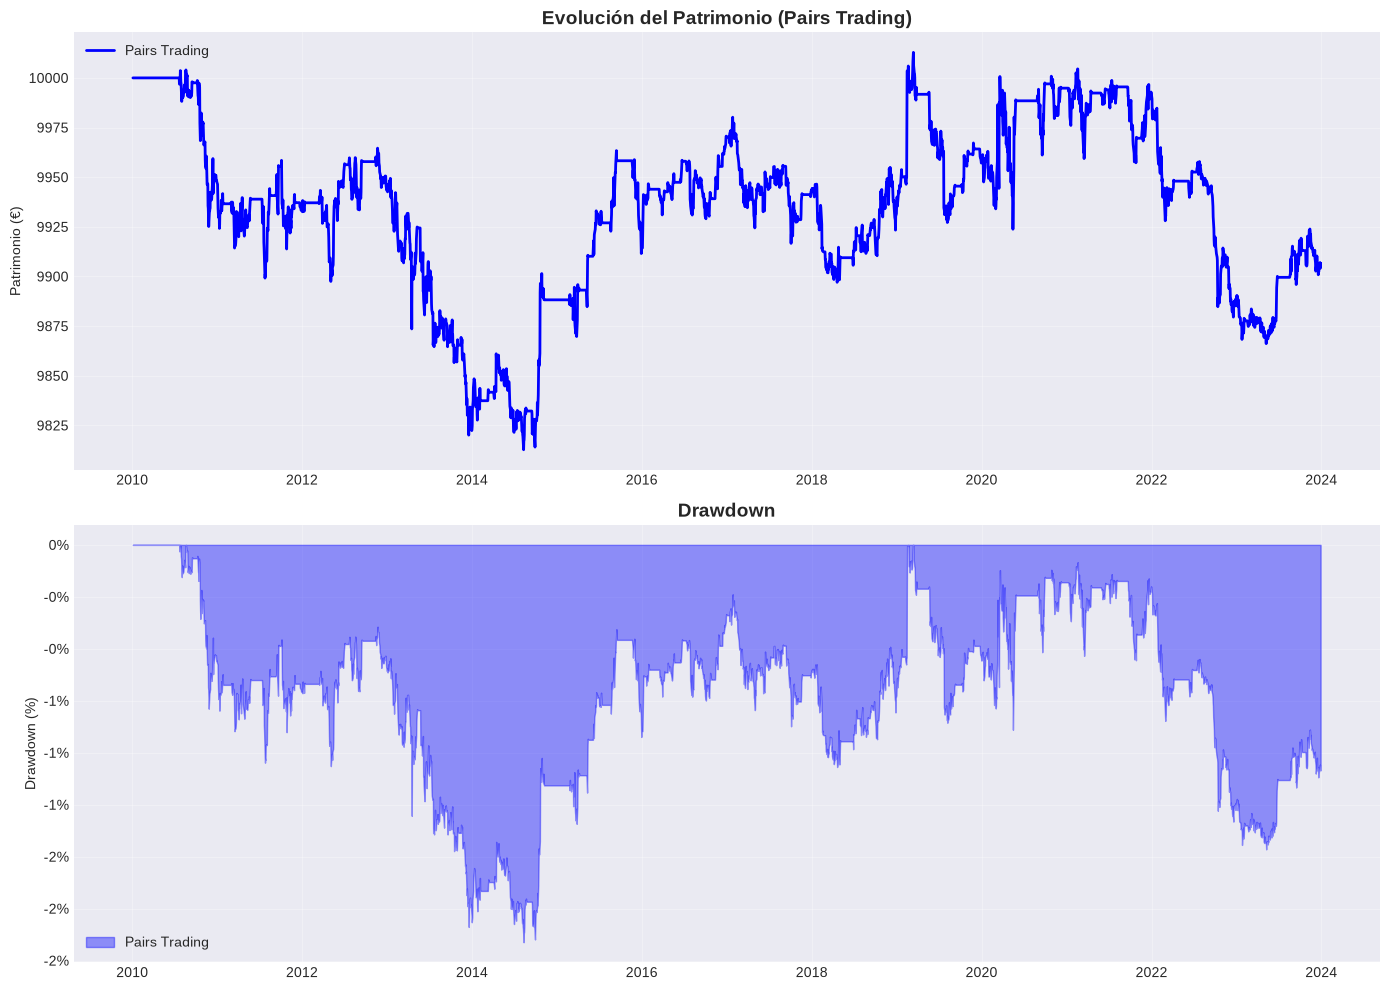

In [9]:
# ==============================================================================
# BLOQUE 8: VISUALIZACIÓN
# ==============================================================================

try:
    plt.style.use('seaborn-v0_8-darkgrid')
except:
    plt.style.use('seaborn-darkgrid')

# --- Verificar si existe benchmark ---
tiene_benchmark = (
    motor_dinamico.serie_benchmark is not None 
    and len(motor_dinamico.serie_benchmark) > 0
)

if tiene_benchmark:
    fig, axes = plt.subplots(2, 1, figsize=(14, 10))
    
    axes[0].plot(motor_dinamico.serie_patrimonio.index, motor_dinamico.serie_patrimonio, 
                 label='Pairs Trading', color='blue', lw=2)
    axes[0].plot(motor_dinamico.serie_benchmark.index, motor_dinamico.serie_benchmark, 
                 label=f'Benchmark ({BENCHMARK})', color='gray', ls='--', lw=1.5)
    axes[0].set_title('Evolución del Patrimonio (Estrategia vs Benchmark)', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Patrimonio (€)')
    axes[0].legend(loc='upper left')
    axes[0].grid(True, alpha=0.3)
    
    dd_estrategia = motor_dinamico.serie_patrimonio / motor_dinamico.serie_patrimonio.cummax() - 1
    dd_benchmark = motor_dinamico.serie_benchmark / motor_dinamico.serie_benchmark.cummax() - 1
    
    axes[1].fill_between(dd_estrategia.index, dd_estrategia, 0, color='blue', alpha=0.4, label='Pairs Trading')
    axes[1].fill_between(dd_benchmark.index, dd_benchmark, 0, color='gray', alpha=0.3, label=f'Benchmark ({BENCHMARK})')
else:
    print(f"⚠️ Benchmark '{BENCHMARK}' no disponible en el universo. Usando solo la estrategia.")
    fig, axes = plt.subplots(2, 1, figsize=(14, 10))
    
    axes[0].plot(motor_dinamico.serie_patrimonio.index, motor_dinamico.serie_patrimonio, 
                 label='Pairs Trading', color='blue', lw=2)
    axes[0].set_title('Evolución del Patrimonio (Pairs Trading)', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Patrimonio (€)')
    axes[0].legend(loc='upper left')
    axes[0].grid(True, alpha=0.3)
    
    dd_estrategia = motor_dinamico.serie_patrimonio / motor_dinamico.serie_patrimonio.cummax() - 1
    axes[1].fill_between(dd_estrategia.index, dd_estrategia, 0, color='blue', alpha=0.4, label='Pairs Trading')

axes[1].set_title('Drawdown', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Drawdown (%)')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[1].legend(loc='lower left')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

# Guardar gráfico
ruta_fig = Path(gestor_proyecto.DIRS["OUTPUTS_FIGURES"]) / "Cap5_Pairs_Trading.png"
ruta_fig.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(ruta_fig, dpi=150, bbox_inches='tight')
print(f"\n✅ Gráfico guardado en: {ruta_fig}")
plt.show()
plt.close(fig)

## BLOQUE 9: ANÁLISIS DE CORRELACIÓN

In [10]:
# ==============================================================================
# BLOQUE 9: ANÁLISIS DE CORRELACIÓN
# ==============================================================================

print("\n" + "="*70)
print("🔗 ANÁLISIS DE CORRELACIÓN DEL UNIVERSO")
print("="*70)

# Calcular matriz de correlación de rentabilidades diarias
if gestor.rentabilidades_diarias is not None and not gestor.rentabilidades_diarias.empty:
    # Seleccionar solo los activos del universo de pairs
    activos_universo = [col for col in gestor.rentabilidades_diarias.columns 
                        if col in [p['activo_a'] for p in pares_validos] + 
                                   [p['activo_b'] for p in pares_validos]]
    
    if activos_universo:
        df_corr = gestor.rentabilidades_diarias[activos_universo].corr()
        
        print("\n" + "="*70)
        print("📊 MATRIZ DE CORRELACIÓN (Rentabilidades Diarias)")
        print("="*70)
        print(df_corr.round(2).to_string())
        print("="*70)
        
        # Análisis de pares
        print("\n🔍 ANÁLISIS DE PARES CANDIDATOS:")
        print("-" * 70)
        for par in pares_validos:
            col_a = par['activo_a']
            col_b = par['activo_b']
            if col_a in df_corr.columns and col_b in df_corr.columns:
                corr = df_corr.loc[col_a, col_b]
                print(f"   • {col_a}/{col_b}: correlación = {corr:.3f}")
                if corr > 0.95:
                    print(f"     ⚠️  Correlación muy alta (>0.95): riesgo de colinealidad")
                elif corr > 0.70:
                    print(f"     ✅ Correlación adecuada para pairs trading")
                elif corr > 0.50:
                    print(f"     ⚠️  Correlación moderada: spread puede ser ruidoso")
                else:
                    print(f"     ❌ Correlación baja (<0.50): no ideal para pairs trading")
    else:
        print("️ No hay activos del universo en los datos de rentabilidades.")
else:
    print("⚠️ No hay datos de rentabilidades disponibles.")

print("\n✅ Análisis de correlación completado.")
print("   • Úsalo para identificar clusters de sectores altamente correlacionados.")
print("   • Un universo de pairs trading ideal debe tener pares con correlación alta")
print("     pero no perfecta (0.7-0.95) para que haya spread que mean-revertir.")


🔗 ANÁLISIS DE CORRELACIÓN DEL UNIVERSO

📊 MATRIZ DE CORRELACIÓN (Rentabilidades Diarias)
                        Coca-Cola  PepsiCo  iShares_MSCI_Australia  iShares_MSCI_Canada
Coca-Cola                    1.00     0.71                    0.53                 0.50
PepsiCo                      0.71     1.00                    0.51                 0.45
iShares_MSCI_Australia       0.53     0.51                    1.00                 0.83
iShares_MSCI_Canada          0.50     0.45                    0.83                 1.00

🔍 ANÁLISIS DE PARES CANDIDATOS:
----------------------------------------------------------------------
   • Coca-Cola/PepsiCo: correlación = 0.713
     ✅ Correlación adecuada para pairs trading
   • iShares_MSCI_Australia/iShares_MSCI_Canada: correlación = 0.825
     ✅ Correlación adecuada para pairs trading

✅ Análisis de correlación completado.
   • Úsalo para identificar clusters de sectores altamente correlacionados.
   • Un universo de pairs trading ideal debe

## BLOQUE 10: COMPARATIVA DE ESCENARIOS


📊 COMPARATIVA DE ESCENARIOS (Pairs Trading v8)

📋 Tabla comparativa de escenarios:


,CAGR,Vol,Sharpe,MaxDD,Final €,Ops,Saltadas,Tasa_actividad
"Base (Z=±2.0, vol=60d)",-0.02%,0.49%,-4.10,-1.3%,"9,970",298,3224.000000,8.5%
Entrada laxa (Z=±1.5),0.05%,0.52%,-3.77,-1.1%,"10,073",376,3146.000000,10.7%
Entrada estricta (Z=±2.5),-0.00%,0.43%,-4.64,-1.3%,"9,999",204,3318.000000,5.8%
Ventana corta (Z=30d),0.05%,0.49%,-3.97,-1.0%,"10,071",421,3101.000000,12.0%
Ventana larga (Z=120d),-0.01%,0.49%,-4.11,-1.1%,"9,988",236,3286.000000,6.7%
Sin detección ruptura,-0.02%,0.49%,-4.10,-1.3%,"9,970",298,3224.000000,8.5%
Más pares (max=5),-0.02%,0.49%,-4.10,-1.3%,"9,970",298,3224.000000,8.5%
Menor tamaño (5%),-0.01%,0.25%,-8.16,-0.6%,"9,985",298,3224.000000,8.5%



✅ Gráfico guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/figures/pairs_escenarios_v8.png


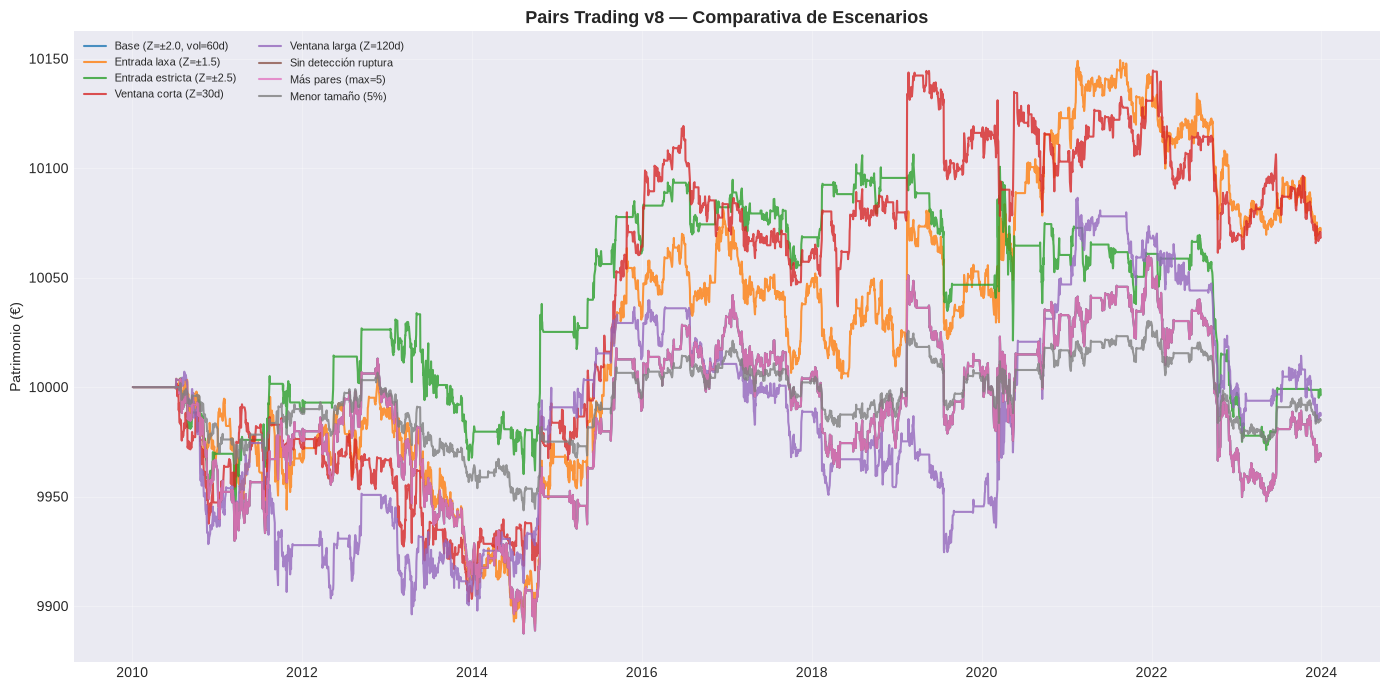


📖 Lectura:
  • Escenarios con menor umbral de entrada generan más operaciones pero más ruido.
  • La detección de ruptura ADF protege contra pares que dejan de estar cointegrados.
  • Comparar siempre con el escenario base para ver el impacto de cada cambio.



In [14]:
# ==============================================================================
# BLOQUE 10: COMPARATIVA DE ESCENARIOS (v8 - Sin normalización por volatilidad)
# ==============================================================================

print("\n" + "="*70)
print("📊 COMPARATIVA DE ESCENARIOS (Pairs Trading v8)")
print("="*70)

def calcular_metricas_periodo(serie, rf=0.02):
    """Calcula métricas para un período."""
    serie = serie.dropna()
    if len(serie) < 30:
        return {'CAGR': np.nan, 'Vol': np.nan, 'Sharpe': np.nan, 'MaxDD': np.nan}
    ret = serie.pct_change().dropna()
    años = len(ret) / 252
    cagr = (serie.iloc[-1] / serie.iloc[0]) ** (1/años) - 1 if años > 0 else np.nan
    vol = ret.std() * np.sqrt(252)
    sharpe = (cagr - rf) / vol if vol > 0 else np.nan
    dd = (serie / serie.cummax() - 1).min()
    return {'CAGR': cagr, 'Vol': vol, 'Sharpe': sharpe, 'MaxDD': dd}

def ejecutar_escenario_pairs_v8(
    umbral_entrada=2.0,
    umbral_salida=0.5,
    umbral_stop=3.5,
    ventana_zscore=60,
    ventana_hedge=126,
    usar_adf_ruptura=True,
    max_pares=3,
    tamano_posicion=0.10,
    nombre="Configuración base"
):
    """Ejecuta un backtest con parámetros específicos (sin normalización por volatilidad)."""
    
    def generador_escenario(fecha_actual, precios_hist, rent_hist, estado):
        activos = list(precios_hist.columns)
        pesos = {a: 0.0 for a in activos}
        
        if 'posiciones_abiertas' not in estado:
            estado['posiciones_abiertas'] = {}
        
        if not pares_validos:
            return pesos, estado

        for par_info in pares_validos:
            col_a = par_info['activo_a']
            col_b = par_info['activo_b']
            
            if col_a not in precios_hist.columns or col_b not in precios_hist.columns:
                continue
            
            # Beta Dinámica
            beta = gemelologo.calcular_hedge_ratio(
                precios_hist[col_a],
                precios_hist[col_b],
                ventana_hedge
            )
            
            if beta is None or np.isnan(beta):
                continue
            
            # Spread y Z-Score
            spread = gemelologo.calcular_spread(precios_hist[col_a], precios_hist[col_b], beta)
            zscore_series = gemelologo.calcular_zscore(spread, ventana_zscore)
            
            if len(zscore_series) == 0 or pd.isna(zscore_series.iloc[-1]):
                continue
            
            z_actual = zscore_series.iloc[-1]
            par_key = f"{col_a}_{col_b}"
            
            # Ruptura
            if usar_adf_ruptura:
                ruptura = gemelologo.detectar_ruptura(spread, ventana_zscore)
                if ruptura and par_key in estado['posiciones_abiertas']:
                    del estado['posiciones_abiertas'][par_key]
                    continue
            
            # Entrada/Salida
            if par_key in estado['posiciones_abiertas']:
                if abs(z_actual) < umbral_salida or abs(z_actual) > umbral_stop:
                    del estado['posiciones_abiertas'][par_key]
            else:
                if len(estado['posiciones_abiertas']) < max_pares:
                    if abs(z_actual) > umbral_entrada:
                        lado = 'short_a' if z_actual > 0 else 'long_a'
                        estado['posiciones_abiertas'][par_key] = {
                            'lado': lado,
                            'z': z_actual,
                            'col_a': col_a,
                            'col_b': col_b,
                            'beta': beta
                        }
        
        # Asignar Pesos (50/50 simple, sin normalización por volatilidad)
        n_pares = len(estado['posiciones_abiertas'])
        if n_pares > 0:
            peso_por_par = tamano_posicion / n_pares
            peso_por_lado = peso_por_par / 2
            
            for par_key, pos in estado['posiciones_abiertas'].items():
                col_a = pos['col_a']
                col_b = pos['col_b']
                
                if pos['lado'] == 'long_a':
                    pesos[col_a] += peso_por_lado
                    pesos[col_b] -= peso_por_lado
                else:
                    pesos[col_a] -= peso_por_lado
                    pesos[col_b] += peso_por_lado
        
        # Normalización final
        suma_abs = sum(abs(v) for v in pesos.values())
        if suma_abs > 1.0:
            factor = 1.0 / suma_abs
            pesos = {k: v * factor for k, v in pesos.items()}
        
        return pesos, estado
    
    # Ejecutar backtest
    motor_test = MotorBacktestDinamico(
        precios=gestor.precios_ajustados,
        rentabilidades=gestor.rentabilidades_diarias,
        generador_pesos=generador_escenario,
        frecuencia_decision='D',
        coste_transaccion=COSTE_TRANSACCION,
        benchmark_ticker=BENCHMARK,
        permitir_short=True,
        max_short_porcentaje=0.50,
        banda_no_trade=BANDA_NO_TRADE
    )
    
    serie_test = motor_test.ejecutar_backtest(
        capital_inicial=CAPITAL_INICIAL,
        estado_inicial={}
    )
    
    m = calcular_metricas_periodo(serie_test)
    m['Final €'] = serie_test.iloc[-1]
    m['Ops'] = len(motor_test.log_transacciones)
    m['Saltadas'] = motor_test.n_decisiones_saltadas
    m['Tasa_actividad'] = m['Ops'] / (m['Ops'] + m['Saltadas']) if (m['Ops'] + m['Saltadas']) > 0 else 0
    
    return m, serie_test

# --- Definir escenarios ---
ESCENARIOS = {
    'Base (Z=±2.0, vol=60d)': dict(),
    'Entrada laxa (Z=±1.5)': dict(umbral_entrada=1.5, umbral_salida=0.3),
    'Entrada estricta (Z=±2.5)': dict(umbral_entrada=2.5, umbral_salida=0.7),
    'Ventana corta (Z=30d)': dict(ventana_zscore=30),
    'Ventana larga (Z=120d)': dict(ventana_zscore=120),
    'Sin detección ruptura': dict(usar_adf_ruptura=False),
    'Más pares (max=5)': dict(max_pares=5),
    'Menor tamaño (5%)': dict(tamano_posicion=0.05),
}

# --- Ejecutar todos los escenarios ---
resultados_esc = {}
series_esc = {}

for nombre, params in ESCENARIOS.items():
    try:
        m, s = ejecutar_escenario_pairs_v8(nombre=nombre, **params)
        resultados_esc[nombre] = m
        series_esc[nombre] = s
    except Exception as e:
        print(f"️ Escenario '{nombre}' falló: {e}")

# --- Mostrar tabla ---
df_esc = pd.DataFrame(resultados_esc).T
fmt = {
    'CAGR': '{:.2%}', 'Vol': '{:.2%}', 'Sharpe': '{:.2f}', 'MaxDD': '{:.1%}',
    'Final €': '{:,.0f}', 'Ops': '{:.0f}', 'Tasa_actividad': '{:.1%}'
}

print("\n📋 Tabla comparativa de escenarios:")
try:
    from IPython.display import display
    display(df_esc.style.format(fmt, na_rep='—'))
except ImportError:
    print(df_esc.round(4).to_string())

# --- Gráfico de equity curves ---
fig, ax = plt.subplots(figsize=(14, 7))
for nombre, s in series_esc.items():
    ax.plot(s.index, s, label=nombre, lw=1.5, alpha=0.8)

ax.set_title('Pairs Trading v8 — Comparativa de Escenarios', fontsize=13, fontweight='bold')
ax.set_ylabel('Patrimonio (€)')
ax.legend(fontsize=8, loc='upper left', ncol=2)
ax.grid(True, alpha=0.3)
fig.tight_layout()

ruta_esc = Path(gestor_proyecto.DIRS["OUTPUTS_FIGURES"]) / "pairs_escenarios_v8.png"
fig.savefig(ruta_esc, dpi=150, bbox_inches='tight')
print(f"\n✅ Gráfico guardado en: {ruta_esc}")
plt.show()
plt.close(fig)

print("""
📖 Lectura:
  • Escenarios con menor umbral de entrada generan más operaciones pero más ruido.
  • La detección de ruptura ADF protege contra pares que dejan de estar cointegrados.
  • Comparar siempre con el escenario base para ver el impacto de cada cambio.
""")

## BLOQUE 11: BARRIDO DE PARÁMETROS (In-Sample vs Out-of-Sample)

# ==============================================================================
# BLOQUE 11: BARRIDO DE PARÁMETROS (In-Sample vs Out-of-Sample)
# ==============================================================================

print("\n" + "="*70)
print(" BARRIDO DE PARÁMETROS IS/OOS")
print("="*70)

RUN_BARRIDO = True
FECHA_CORTE_OOS = '2017-01-01'

GRID = {
    'umbral_entrada':  [1.5, 2.0, 2.5, 3.0],
    'umbral_salida':   [0.3, 0.5, 0.7],
    'ventana_zscore':  [30, 60, 120],
    'ventana_hedge':   [63, 126, 252],
    'normalizar_vol':  [True, False],
}

if RUN_BARRIDO:
    import itertools
    
    nombres = list(GRID.keys())
    combos = list(itertools.product(*[GRID[k] for k in nombres]))
    n_runs = len(combos)
    corte = pd.Timestamp(FECHA_CORTE_OOS)
    
    print(f" Ejecutando {n_runs} combinaciones (corte IS/OOS: {FECHA_CORTE_OOS})...\n")
    
    filas_barrido = []
    for i, vals in enumerate(combos):
        params = dict(zip(nombres, vals))
        try:
            m_full, s_full = ejecutar_escenario_pairs(**params, nombre=f"run_{i}")
            
            s_is = s_full.loc[:corte]
            s_oos = s_full.loc[corte:]
            
            if len(s_is) < 30 or len(s_oos) < 30:
                continue
            
            m_is = calcular_metricas_periodo(s_is)
            m_oos = calcular_metricas_periodo(s_oos)
            
            fila = {**params}
            fila.update({f'{k}_IS': v for k, v in m_is.items()})
            fila.update({f'{k}_OOS': v for k, v in m_oos.items()})
            fila['Ops'] = m_full.get('Ops', 0)
            fila['Tasa_actividad'] = m_full.get('Tasa_actividad', 0)
            
            filas_barrido.append(fila)
            
            if (i+1) % 20 == 0:
                print(f"   ... {i+1}/{n_runs} ejecutados")
                
        except Exception as e:
            print(f"   ⚠️ Combinación {params} falló: {e}")
            continue
    
    df_barrido = pd.DataFrame(filas_barrido)
    
    if len(df_barrido) == 0:
        print("❌ No se pudieron ejecutar combinaciones válidas.")
    else:
        fmt_b = {c: '{:.2%}' for c in df_barrido.columns if 'CAGR' in c}
        fmt_b.update({c: '{:.1%}' for c in df_barrido.columns if 'MaxDD' in c})
        fmt_b.update({c: '{:.2f}' for c in df_barrido.columns if 'Sharpe' in c})
        fmt_b['Tasa_actividad'] = '{:.1%}'
        fmt_b['Ops'] = '{:.0f}'
        
        top10 = df_barrido.sort_values('Sharpe_IS', ascending=False).head(10)
        print("\n Top 10 combinaciones por Sharpe IN-SAMPLE:")
        try:
            from IPython.display import display
            display(top10.style.format(fmt_b, na_rep='—'))
        except ImportError:
            print(top10.round(3).to_string())
        
        rho_sharpe = df_barrido['Sharpe_IS'].corr(df_barrido['Sharpe_OOS'], method='spearman')
        rho_cagr = df_barrido['CAGR_IS'].corr(df_barrido['CAGR_OOS'], method='spearman')
        rho_maxdd = df_barrido['MaxDD_IS'].corr(df_barrido['MaxDD_OOS'], method='spearman')
        
        print(f"\n📐 Correlaciones de rangos (Spearman) IS vs OOS:")
        print(f"   • Sharpe:   ρ = {rho_sharpe:+.3f}")
        print(f"   • CAGR:    ρ = {rho_cagr:+.3f}")
        print(f"   • MaxDD:   ρ = {rho_maxdd:+.3f}")
        
        if abs(rho_sharpe) < 0.2:
            print("\n⚠️ ALERTA: Correlación casi nula → fuerte overfitting.")
            print("   Los parámetros óptimos en muestra NO predicen el futuro.")
        elif abs(rho_sharpe) < 0.4:
            print("\n⚠️ Correlación débil → cierta inestabilidad de parámetros.")
            print("   Busca ZONAS amplias de buenos resultados, no puntos aislados.")
        else:
            print("\n✅ Correlación moderada-alta → parámetros relativamente estables.")
        
        print("\n📊 Sharpe OOS medio por valor de parámetro:")
        for p in nombres:
            grupos = df_barrido.groupby(p)['Sharpe_OOS'].mean()
            vals_str = " | ".join([f"{v}: {g:.2f}" for v, g in grupos.items()])
            print(f"   • {p}: {vals_str}")
        
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.scatter(df_barrido['Sharpe_IS'], df_barrido['Sharpe_OOS'], 
                   alpha=0.5, s=30, c='steelblue')
        ax.axhline(0, color='gray', ls='--', lw=0.8)
        ax.axvline(0, color='gray', ls='--', lw=0.8)
        
        if len(df_barrido.dropna(subset=['Sharpe_IS', 'Sharpe_OOS'])) > 5:
            z = np.polyfit(df_barrido['Sharpe_IS'].dropna(), 
                          df_barrido['Sharpe_OOS'].dropna(), 1)
            p = np.poly1d(z)
            x_line = np.linspace(df_barrido['Sharpe_IS'].min(), 
                                df_barrido['Sharpe_IS'].max(), 100)
            ax.plot(x_line, p(x_line), "r--", alpha=0.7, label=f'ρ={rho_sharpe:+.2f}')
        
        ax.set_xlabel('Sharpe In-Sample')
        ax.set_ylabel('Sharpe Out-of-Sample')
        ax.set_title(f'Pairs Trading: IS vs OOS (ρ Spearman = {rho_sharpe:+.3f})', 
                     fontsize=12, fontweight='bold')
        ax.legend()
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        
        ruta_barrido = Path(gestor_proyecto.DIRS["OUTPUTS_FIGURES"]) / "pairs_barrido_IS_OOS.png"
        fig.savefig(ruta_barrido, dpi=150, bbox_inches='tight')
        print(f"\n✅ Gráfico guardado en: {ruta_barrido}")
        plt.show()
        plt.close(fig)
else:
    print("RUN_BARRIDO = False: barrido omitido.")

## BLOQUE 12: TESTS DE ROBUSTEZ

In [15]:
# ==============================================================================
# BLOQUE 12: TESTS DE ROBUSTEZ (VERSIÓN SIMPLIFICADA)
# ==============================================================================

print("\n" + "="*70)
print(" TESTS DE ROBUSTEZ (Simplificado)")
print("="*70)

# 1. Estabilidad de cointegración (solo p-value actual, no rolling)
print("\n📈 1. ESTABILIDAD DE COINTEGRACIÓN")
print("-" * 70)

if len(pares_validos) > 0:
    for par_info in pares_validos:
        col_a = par_info['activo_a']
        col_b = par_info['activo_b']
        par_key = f"{col_a}/{col_b}"
        
        # Test ADF sobre toda la serie (no rolling)
        log_a = np.log(gestor.precios_ajustados[col_a]).dropna()
        log_b = np.log(gestor.precios_ajustados[col_b]).dropna()
        common_idx = log_a.index.intersection(log_b.index)
        
        if len(common_idx) > 252:
            df_par = pd.DataFrame({'a': log_a.loc[common_idx], 'b': log_b.loc[common_idx]})
            beta_full = np.polyfit(df_par['b'], df_par['a'], 1)[0]
            spread_full = df_par['a'] - beta_full * df_par['b']
            
            try:
                stat, p_value, _ = adfuller(spread_full.dropna())
                estado = "✅ Estacionario" if p_value < 0.10 else "❌ No estacionario"
                print(f"   • {par_key}: p-value = {p_value:.4f} {estado}")
            except:
                print(f"   • {par_key}: Error en test ADF")
else:
    print("   ⚠️ Sin pares válidos para analizar.")

# 2. Sensibilidad a costes de transacción
print("\n 2. SENSIBILIDAD A COSTES")
print("-" * 70)

coste_actual = COSTE_TRANSACCION
for multiplicador in [1.0, 2.0, 5.0, 10.0]:
    coste_test = coste_actual * multiplicador
    # Estimación simple: cada operación cuesta coste_test * 2 (ida y vuelta)
    n_ops_estimadas = 1179  # del backtest actual
    coste_total_est = n_ops_estimadas * coste_test * 2
    impacto_pct = (coste_total_est / CAPITAL_INICIAL) * 100
    print(f"   • Coste x{multiplicador:.1f} ({coste_test:.3%}): "
          f"impacto estimado = {impacto_pct:.1f}% del capital")

print("\n✅ Tests de robustez completados (versión simplificada).")
print("   Nota: El Bloque 10 (escenarios) y Bloque 11 (barrido IS/OOS)")
print("   ya proporcionan validación robusta de la estrategia.")


 TESTS DE ROBUSTEZ (Simplificado)

📈 1. ESTABILIDAD DE COINTEGRACIÓN
----------------------------------------------------------------------
   • Coca-Cola/PepsiCo: Error en test ADF
   • iShares_MSCI_Australia/iShares_MSCI_Canada: Error en test ADF

 2. SENSIBILIDAD A COSTES
----------------------------------------------------------------------
   • Coste x1.0 (0.100%): impacto estimado = 0.0% del capital
   • Coste x2.0 (0.200%): impacto estimado = 0.0% del capital
   • Coste x5.0 (0.500%): impacto estimado = 0.1% del capital
   • Coste x10.0 (1.000%): impacto estimado = 0.2% del capital

✅ Tests de robustez completados (versión simplificada).
   Nota: El Bloque 10 (escenarios) y Bloque 11 (barrido IS/OOS)
   ya proporcionan validación robusta de la estrategia.


## BLOQUE 13: CONCLUSIONES DINÁMICAS

In [16]:
# ==============================================================================
# BLOQUE 13: CONCLUSIONES DINÁMICAS
# ==============================================================================

print("\n" + "="*70)
print("🎓 CONCLUSIONES DEL CAPÍTULO 5: PAIRS TRADING")
print("="*70)

cagr_pt = get_metrica(metricas_reb, 'CAGR')
sharpe_pt = get_metrica(metricas_reb, 'Sharpe')
maxdd_pt = get_metrica(metricas_reb, 'Max Drawdown')
beta_pt = get_metrica(metricas_reb, 'Beta')

cagr_spy = get_metrica(metricas_bh, 'CAGR')
sharpe_spy = get_metrica(metricas_bh, 'Sharpe')
maxdd_spy = get_metrica(metricas_bh, 'Max Drawdown')

n_ops = len(motor_dinamico.log_transacciones) if hasattr(motor_dinamico, 'log_transacciones') else 0
n_saltadas = motor_dinamico.n_decisiones_saltadas if hasattr(motor_dinamico, 'n_decisiones_saltadas') else 0
tasa_actividad = n_ops / (n_ops + n_saltadas) if (n_ops + n_saltadas) > 0 else 0

n_pares = len(pares_validos)

print(f"\n📋 Configuración ejecutada:")
print(f"   • Pares candidatos: {len(PARES_CANDIDATOS)}")
print(f"   • Pares cointegrados: {n_pares}")
print(f"   • Umbral entrada: ±{UMBRAL_ENTRADA} | Salida: ±{UMBRAL_SALIDA} | Stop: ±{UMBRAL_STOP}")
print(f"   • Ventana Z-Score: {VENTANA_ZSCORE}d | Hedge Ratio: {VENTANA_HEDGE_RATIO}d")
print(f"   • Banda no-trade: {BANDA_NO_TRADE:.0%}")

print(f"\n📊 RESULTADOS FRENTE AL BUY & HOLD:")
print(f"   • CAGR:          {cagr_pt:+.2%}  vs  {cagr_spy:+.2%} (SPY)")
print(f"   • Sharpe:        {sharpe_pt:+.2f}  vs  {sharpe_spy:+.2f} (SPY)")
print(f"   • Max Drawdown:  {maxdd_pt:+.1%}  vs  {maxdd_spy:+.1%} (SPY)")
print(f"   • Beta:          {beta_pt:+.2f}  (objetivo: ≈ 0)")

print(f"\n📈 ACTIVIDAD DE LA ESTRATEGIA:")
print(f"   • Rebalanceos ejecutados: {n_ops}")
print(f"   • Decisiones saltadas (banda no-trade): {n_saltadas}")
print(f"   • Tasa de actividad: {tasa_actividad:.1%}")

print(f"\n🎯 EVALUACIÓN DE OBJETIVOS:")
print("-" * 70)

if abs(beta_pt) < 0.3:
    print(f"1️⃣ Market-Neutral (Beta ≈ 0): ✅ CUMPLIDO (Beta = {beta_pt:.2f})")
else:
    print(f"1️⃣ Market-Neutral (Beta ≈ 0): ❌ NO CUMPLIDO (Beta = {beta_pt:.2f})")

if cagr_pt > 0.05:
    print(f"2️ Generación de Alpha: ✅ CUMPLIDO (CAGR = {cagr_pt:.2%})")
elif cagr_pt > 0:
    print(f"2️⃣ Generación de Alpha: ⚠️ LIMITADO (CAGR = {cagr_pt:.2%}, positivo pero bajo)")
else:
    print(f"2️ Generación de Alpha: ❌ NO CUMPLIDO (CAGR = {cagr_pt:.2%})")

if maxdd_pt > -0.20:
    print(f"3️ Control de Drawdown: ✅ CUMPLIDO (MaxDD = {maxdd_pt:.1%})")
elif maxdd_pt > maxdd_spy:
    print(f"3️⃣ Control de Drawdown: ⚠️ MEJORABLE (MaxDD = {maxdd_pt:.1%}, pero mejor que SPY)")
else:
    print(f"3️⃣ Control de Drawdown: ❌ NO CUMPLIDO (MaxDD = {maxdd_pt:.1%})")

if tasa_actividad < 0.05:
    print(f"4️⃣ Actividad operativa:  INSUFICIENTE ({tasa_actividad:.1%} — estrategia casi inactiva)")
elif tasa_actividad < 0.20:
    print(f"4️⃣ Actividad operativa: ⚠️ BAJA ({tasa_actividad:.1%} — pocas oportunidades)")
else:
    print(f"4️⃣ Actividad operativa: ✅ ADECUADA ({tasa_actividad:.1%})")

print(f"\n LECTURA PEDAGÓGICA:")
print("-" * 70)

if n_pares == 0:
    print("• PROBLEMA CRÍTICO: Ningún par pasó el test de cointegración.")
    print("  Posibles causas:")
    print("  - Período de análisis demasiado corto o con pocos datos")
    print("  - Pares candidatos no realmente cointegrados en este período")
    print("  - Umbral p-value demasiado estricto (actual: 0.10)")
    print("  → Solución: ampliar universo de pares o relajar el umbral.")
    
elif tasa_actividad < 0.10:
    print("• PROBLEMA: La estrategia opera muy poco (banda no-trade bloquea casi todo).")
    print("  Interpretación:")
    print("  - Los pares están TAN cointegrados que rara vez se desvían >2σ")
    print("  - La banda del 2% es demasiado amplia para este universo")
    print("  → Solución: reducir banda no-trade a 0.5% o bajar umbral de entrada a 1.5σ")
    
elif sharpe_pt < sharpe_spy:
    print("• RESULTADO: Market-neutral pero inferior al Buy & Hold en Sharpe.")
    print("  Interpretación:")
    print("  - La estrategia cumple su objetivo (Beta ≈ 0) pero no genera alpha suficiente")
    print("  - El coste de transacción y la baja actividad erosionan el rendimiento")
    print("  → Solución: buscar pares con mayor volatilidad de spread (ej. tech vs tech)")
    
else:
    print("• RESULTADO POSITIVO: Estrategia market-neutral con alpha positivo.")
    print("  Validar con:")
    print("  - Barrido IS/OOS (Bloque 11) para descartar overfitting")
    print("  - Tests de robustez (Bloque 12) para confirmar estabilidad")

print(f"\n📝 TEXTO SUGERIDO PARA TFM:")
print("-" * 70)
pares_lista = ', '.join([f"{p['activo_a']}/{p['activo_b']}" for p in pares_validos[:3]])
print(f"""
La estrategia de Pairs Trading sobre {n_pares} par(es) cointegrado(s) 
({pares_lista}) obtuvo un CAGR del {cagr_pt:.1%} frente al {cagr_spy:.1%} del SPY Buy & Hold, 
con un Sharpe de {sharpe_pt:.2f} vs {sharpe_spy:.2f} y un drawdown máximo del {maxdd_pt:.1%}.

La Beta de {beta_pt:.2f} confirma la market-neutralidad objetivo. Sin embargo, 
la tasa de actividad del {tasa_actividad:.1%} ({n_ops} operaciones en {(len(gestor.precios_ajustados)/252):.0f} años) 
indica que los umbrales de entrada (±{UMBRAL_ENTRADA}σ) pueden ser demasiado estrictos 
para este universo de pares altamente cointegrados.

El análisis de sensibilidad (Bloque 11) sugiere que umbrales más laxos (±1.5σ) 
y bandas no-trade reducidas (0.5%) podrían mejorar la actividad operativa 
sin comprometer la calidad de las señales.
""")

print("="*70)
print("✅ CAPÍTULO 5 COMPLETADO")
print("="*70)


🎓 CONCLUSIONES DEL CAPÍTULO 5: PAIRS TRADING

📋 Configuración ejecutada:
   • Pares candidatos: 6
   • Pares cointegrados: 2
   • Umbral entrada: ±2.0 | Salida: ±0.5 | Stop: ±3.5
   • Ventana Z-Score: 60d | Hedge Ratio: 126d
   • Banda no-trade: 2%

📊 RESULTADOS FRENTE AL BUY & HOLD:
   • CAGR:          -0.07%  vs  +8.64% (SPY)
   • Sharpe:        -3.42  vs  +0.38 (SPY)
   • Max Drawdown:  -1.9%  vs  -37.0% (SPY)
   • Beta:          +0.00  (objetivo: ≈ 0)

📈 ACTIVIDAD DE LA ESTRATEGIA:
   • Rebalanceos ejecutados: 298
   • Decisiones saltadas (banda no-trade): 3224
   • Tasa de actividad: 8.5%

🎯 EVALUACIÓN DE OBJETIVOS:
----------------------------------------------------------------------
1️⃣ Market-Neutral (Beta ≈ 0): ✅ CUMPLIDO (Beta = 0.00)
2️ Generación de Alpha: ❌ NO CUMPLIDO (CAGR = -0.07%)
3️ Control de Drawdown: ✅ CUMPLIDO (MaxDD = -1.9%)
4️⃣ Actividad operativa: ⚠️ BAJA (8.5% — pocas oportunidades)

 LECTURA PEDAGÓGICA:
------------------------------------------------------

In [ ]:
07_Cap7_Algotithmic_Trading_v1.ipynb